# Kdy letět s termokamerou: teplota povrchů ze skutečného počasí

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/thermal_timing_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kdy letět s termokamerou](https://openskylab.space/edu_viz_thermal_timing.html) · [English version](thermal_timing_en.ipynb)

Vizuál ukazuje, jak se voda, louka, asfalt, les a fotovoltaika během dne ohřívají a chladnou a kdy se dva povrchy v termosnímku slijí. Tady stejný typ modelu (energetická bilance povrchu s vedením tepla do hloubky) poženeš skutečným hodinovým počasím za poslední měsíce v Suchdole a hledáš nejlepší čas letu podle úlohy.

**Cíl:** spočítat denní chod teploty povrchů ze skutečného záření, teploty, vlhkosti, oblačnosti a větru, najít časy, kdy se dva povrchy teplotně překříží, porovnat jasný a zatažený den, ukázat vliv větru a emisivity nastavené v kameře a najít hodiny vhodné pro kontrolu fotovoltaiky.

**Data:** hodinová teplota a vlhkost vzduchu, globální záření na vodorovnou i skloněnou plochu, oblačnost, vítr v 10 m a teplota povrchu půdy z Open-Meteo pro kampus v Suchdole, co služba vrátí za posledních 92 dní, obvykle dva až tři měsíce (model počasí, ne měření na místě); tepelné vlastnosti materiálů z literatury.

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a skutečné počasí

počasí 31. 07. až 31. 10. 2026, 2232 hodin
nejslunečnější den 2026-08-15 (6.7 kWh/m²), nejzataženější 2026-10-25 (0.4 kWh/m²)


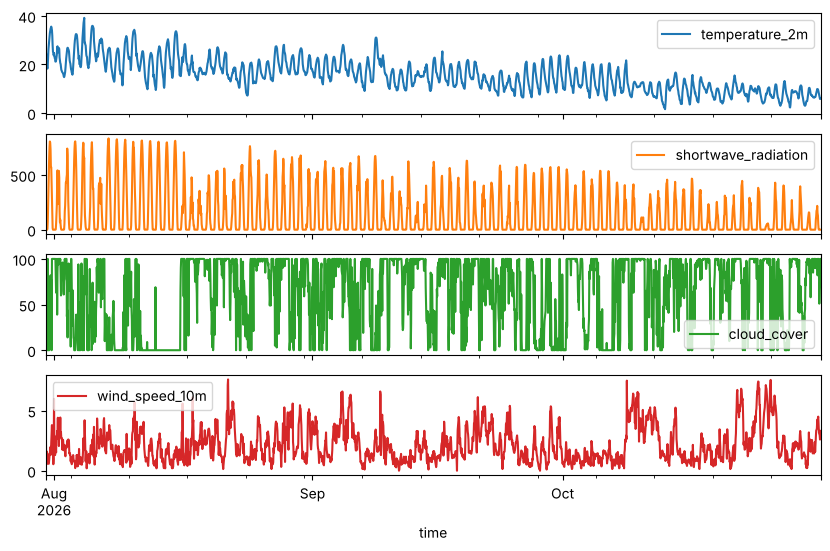

In [1]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

LAT, LON = 50.130, 14.373     # ◀ parametr: místo (kampus v Suchdole)
TILT, AZ = 35, 0              # ◀ parametr: sklon a azimut fotovoltaiky (°; azimut 0 = jih, −90 = východ, 90 = západ)

def weather(lat, lon, tilt, az):
    j = open_meteo({"latitude": lat, "longitude": lon, "past_days": 92, "forecast_days": 1,
                    "hourly": "temperature_2m,relative_humidity_2m,shortwave_radiation,global_tilted_irradiance,cloud_cover,wind_speed_10m,soil_temperature_0cm",
                    "tilt": tilt, "azimuth": az, "timezone": "Europe/Prague", "wind_speed_unit": "ms"})
    w = pd.DataFrame(j["hourly"]); w["time"] = pd.to_datetime(w.time)
    return w.set_index("time").dropna()

w = weather(LAT, LON, TILT, AZ)
days = w.shortwave_radiation.resample("D").sum() / 1000           # kWh/m² za den
days = days.iloc[14:-1]                                          # prvních 14 dní je rozběh modelu, poslední den je neúplný
SUNNY, CLOUDY = days.idxmax().date(), days.idxmin().date()
print(f"počasí {w.index[0]:%d. %m.} až {w.index[-1]:%d. %m. %Y}, {len(w)} hodin")
print(f"nejslunečnější den {SUNNY} ({days.max():.1f} kWh/m²), nejzataženější {CLOUDY} ({days.min():.1f} kWh/m²)")
w[["temperature_2m", "shortwave_radiation", "cloud_cover", "wind_speed_10m"]].plot(subplots=True, figsize=(10, 6), legend=True); plt.show()

## 2. Model povrchu a jeden jasný den

Pro každý povrch se každou minutu řeší energetická bilance **Rn = H + LE + G**:

- Rn: pohlcené sluneční záření (1 − albedo) · S plus dlouhovlnná bilance ε (L↓ − σ T⁴). L↓ z oblohy je z teploty a vlhkosti vzduchu (Brutsaert 1975) a z oblačnosti (Crawford a Duchon 1999).
- H: citelné teplo do vzduchu h · (T − Tₐ), h = 5,7 + 3,8 U, kde U je vítr ve 2 m (z větru v 10 m logaritmickým profilem, ×0,75).
- LE: výpar ρ L (q*(T) − qₐ) / (rₐ + r_s); odpor průduchů r_s je u louky 70 s/m, u lesa 100 s/m, voda se vypařuje volně, asfalt a panel vůbec.
- G: teplo do hloubky. Asfalt a půda mají 12 vrstev do 1 m, rybník je promíchaná vrstva vody 1 m, koruny lesa a FV panel jsou tenká vrstva bez vedení do země.

Sluneční záření, teplota, vlhkost, oblačnost a vítr jsou skutečné hodinové hodnoty z Open-Meteo. Model běží od začátku období, prvních 14 dní slouží k rozběhu.

voda × louka: překřížení v 07:36
voda × louka: překřížení v 18:54


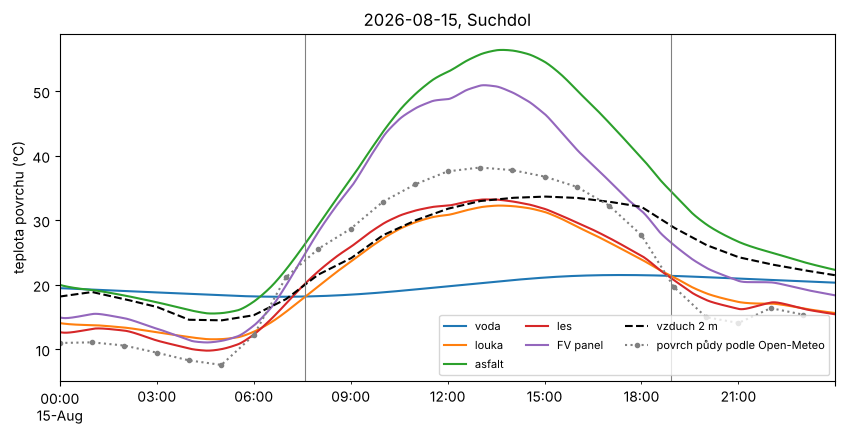

                     voda  louka  asfalt   les  FV panel
2026-08-15 02:00:00  18.9   13.0    17.9  12.2      14.1
2026-08-15 05:00:00  18.3   12.0    16.2  10.9      12.2
2026-08-15 08:00:00  18.4   21.7    32.8  24.1      31.7
2026-08-15 11:00:00  19.5   30.4    51.5  32.0      48.3
2026-08-15 13:00:00  20.5   32.2    56.2  33.2      50.6
2026-08-15 16:00:00  21.5   27.9    47.7  28.5      38.6
2026-08-15 19:00:00  21.3   19.9    31.6  19.1      24.3
2026-08-15 22:00:00  20.7   16.8    24.3  16.9      19.9


In [2]:
SIG = 5.670e-8
# albedo, emisivita, tepelná vodivost k (W/m/K), objemová tepelná kapacita C (J/m³/K), odpor průduchů r_s (s/m; inf = bez výparu),
# node = tepelná kapacita jediné vrstvy (J/m²/K) u povrchů bez vedení do hloubky, rough = násobek přestupu tepla (drsnost), sides = ochlazování z obou stran
SURF = {
    "voda":     dict(alb=0.06, eps=0.99, k=0.0,  C=0.0,    rs=0.0,    node=4.18e6 * 1.0),
    "louka":    dict(alb=0.20, eps=0.98, k=1.2,  C=2.5e6,  rs=70.0),
    "asfalt":   dict(alb=0.08, eps=0.95, k=0.75, C=1.94e6, rs=np.inf),
    "les":      dict(alb=0.12, eps=0.98, k=0.0,  C=0.0,    rs=100.0,  node=3.0e4, rough=3),
    "FV panel": dict(alb=0.30, eps=0.85, k=0.0,  C=0.0,    rs=np.inf, node=1.5e4, sides=2, tilted=1),
}

def qsat(T):
    """Měrná vlhkost nasyceného vzduchu (kg/kg) při teplotě T v kelvinech (Magnus, 1013 hPa)."""
    return 0.622 * 610.94 * np.exp(17.625 * (T - 273.15) / (T - 30.11)) / 101325

def simulate(w, surf=SURF, wind_factor=1.0, dt=60, nl=12, depth=1.0):
    t = (w.index - w.index[0]).total_seconds().values
    ts = np.arange(0, t[-1], dt)
    Ta = np.interp(ts, t, w.temperature_2m.values) + 273.15
    RH = np.interp(ts, t, w.relative_humidity_2m.values) / 100
    S = np.interp(ts, t - 1800, w.shortwave_radiation.values)          # záření je průměr za předchozí hodinu
    S_tilt = np.interp(ts, t - 1800, w.global_tilted_irradiance.values)
    cc = np.interp(ts, t, w.cloud_cover.values) / 100
    U = np.maximum(np.interp(ts, t, w.wind_speed_10m.values) * 0.75 * wind_factor, 0.3)
    e = RH * 610.94 * np.exp(17.625 * (Ta - 273.15) / (Ta - 30.11))
    eps_sky = 1.24 * (e / 100 / Ta) ** (1 / 7) * (1 - cc) + cc
    Ld = eps_sky * SIG * Ta ** 4
    qa = RH * qsat(Ta)
    names = list(surf)
    p = {k: np.array([surf[n].get(k, d) for n in names], float) for k, d in
         [("alb", 0), ("eps", 1), ("k", 0), ("C", 0), ("rs", np.inf), ("node", 0), ("rough", 1), ("sides", 1), ("tilted", 0)]}
    r = 1.0
    while 0.01 * (r ** nl - 1) / (r - 1 + 1e-12) < depth: r += 0.001
    dz = 0.01 * r ** np.arange(nl)                                      # vrstvy od 1 cm, směrem dolů tlustší
    single = p["node"] > 0
    cap = np.outer(p["C"], dz); cap[single, 0] = p["node"][single]; cap[single, 1:] = 1
    kk = np.outer(p["k"], np.ones(nl - 1)) / ((dz[1:] + dz[:-1]) / 2)
    T = np.full((len(names), nl), Ta[: int(3 * 86400 / dt)].mean())
    out = np.empty((len(ts), len(names)))
    rho, cp, L = 1.2, 1005, 2.45e6
    for i in range(len(ts)):
        Ts = T[:, 0]
        h = (5.7 + 3.8 * U[i]) * p["rough"]
        sw = np.where(p["tilted"] > 0, S_tilt[i], S[i])
        Rn = (1 - p["alb"]) * sw + p["eps"] * (Ld[i] - SIG * Ts ** 4) + (p["sides"] - 1) * p["eps"] * SIG * (Ta[i] ** 4 - Ts ** 4)
        H = h * p["sides"] * (Ts - Ta[i])
        LE = np.where(np.isinf(p["rs"]), 0.0, rho * L * (qsat(Ts) - qa[i]) / (rho * cp / h + np.where(np.isinf(p["rs"]), 0, p["rs"])))
        flux = kk * (T[:, :-1] - T[:, 1:])
        dT = np.zeros_like(T)
        dT[:, 0] = Rn - H - LE - flux[:, 0]
        dT[:, 1:-1] = flux[:, :-1] - flux[:, 1:]
        dT[:, -1] = flux[:, -1]
        T += dt * dT / cap
        out[i] = T[:, 0]
    idx = w.index[0] + pd.to_timedelta(ts, "s")
    res = pd.DataFrame(out - 273.15, index=idx, columns=names)
    res.attrs["Ld"] = pd.Series(Ld, index=idx); res.attrs["Ta"] = pd.Series(Ta - 273.15, index=idx)
    return res

def crossings(a, b):
    """Časy, kdy rozdíl a − b mění znaménko (lineární interpolace mezi minutami)."""
    d = (a - b).values; i = np.where(np.sign(d[:-1]) * np.sign(d[1:]) < 0)[0]
    return [a.index[k] + (a.index[k + 1] - a.index[k]) * (d[k] / (d[k] - d[k + 1])) for k in i]

T = simulate(w)
DAY = SUNNY                   # ◀ parametr: den, např. "2026-09-10"; výchozí je nejslunečnější den
A, B = "voda", "louka"        # ◀ parametr: dvojice povrchů
d = T.loc[str(DAY)]
ax = d.plot(figsize=(10, 4.5))
T.attrs["Ta"].loc[str(DAY)].plot(ax=ax, color="k", ls="--", label="vzduch 2 m")
w.soil_temperature_0cm.loc[str(DAY)].plot(ax=ax, color="gray", ls=":", marker=".", label="povrch půdy podle Open-Meteo")
for c in crossings(d[A], d[B]):
    ax.axvline(c, color="gray", lw=0.8); print(f"{A} × {B}: překřížení v {c:%H:%M}")
ax.set_ylabel("teplota povrchu (°C)"); ax.set_xlabel(""); ax.set_title(f"{DAY}, Suchdol"); ax.legend(ncol=3, fontsize=8); plt.show()
print(d.resample("h").mean().iloc[[2, 5, 8, 11, 13, 16, 19, 22]].round(1))

> **✏️ Úkol 1.** Odečti časy obou překřížení vody a louky. Proč je voda v noci teplejší než louka a v poledne chladnější? Porovnej modelovanou louku s teplotou povrchu půdy z Open-Meteo (tečkovaně): kde se liší nejvíc a čím to může být (je to taky model, ne měření)? Zkus dvojici asfalt × les.

*Tvoje odpověď:* 

## 3. Jasno, nebo zataženo?

Porovnáme nejslunečnější a nejzataženější den ze stažených dat. Amplituda je rozdíl mezi denním maximem a minimem teploty povrchu.

2026-08-15: záření 6.7 kWh/m², oblačnost 0 %, vítr 1.0 m/s
2026-10-25: záření 0.4 kWh/m², oblačnost 88 %, vítr 5.3 m/s


          2026-08-15: amplituda  2026-10-25: amplituda
voda                        3.4                    1.2
louka                      20.7                    7.0
asfalt                     40.9                    8.2
les                        23.4                    8.3
FV panel                   39.9                    9.0
{'2026-08-15: voda − louka ve 3:00': 6.2, '2026-10-25: voda − louka ve 3:00': 3.1}


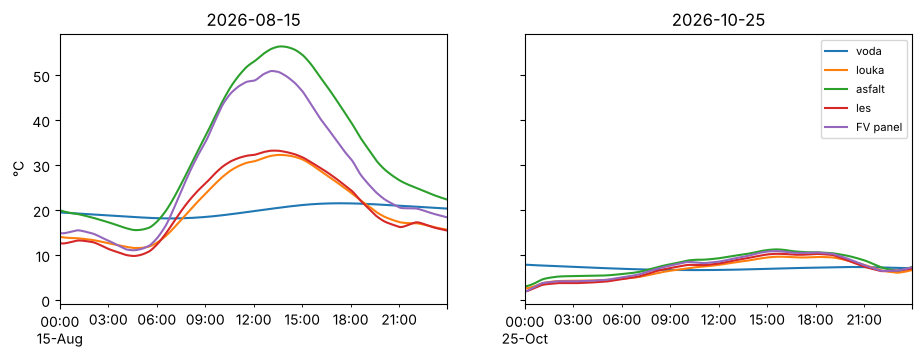

In [3]:
DAYS = [SUNNY, CLOUDY]        # ◀ parametr: dny k porovnání (můžeš přidat třetí, např. "2026-09-20")
rows = {}
for day in DAYS:
    d = T.loc[str(day)]
    rows[f"{day}: amplituda"] = d.max() - d.min()
    rows[f"{day}: voda − louka ve 3:00"] = d.between_time("02:55", "03:05").mean()["voda"] - d.between_time("02:55", "03:05").mean()["louka"]
    print(f"{day}: záření {days.loc[pd.Timestamp(day)]:.1f} kWh/m², oblačnost {w.cloud_cover.loc[str(day)].mean():.0f} %, vítr {w.wind_speed_10m.loc[str(day)].mean():.1f} m/s")
print(pd.DataFrame({k: v for k, v in rows.items() if "amplituda" in k}).round(1))
print({k: round(float(v), 1) for k, v in rows.items() if "louka" in k})
fig, ax = plt.subplots(1, len(DAYS), figsize=(11, 3.5), sharey=True)
for a, day in zip(np.atleast_1d(ax), DAYS):
    T.loc[str(day)].plot(ax=a, legend=False); a.set_title(str(day))
np.atleast_1d(ax)[0].set_ylabel("°C"); np.atleast_1d(ax)[-1].legend(fontsize=8); plt.show()

> **✏️ Úkol 2.** O kolik se v zatažený den zmenšila amplituda asfaltu a vody? Co se stalo s rozdílem voda − louka v noci? Vysvětli roli slunečního záření ve dne a dlouhovlnného záření oblačnosti v noci.

*Tvoje odpověď:* 

## 4. Kalendář kontrastu: kdy letět

Pro každý den a hodinu spočítáme rozdíl teplot dvojice povrchů. Bílá místa jsou překřížení, kdy se povrchy v termosnímku slijí.

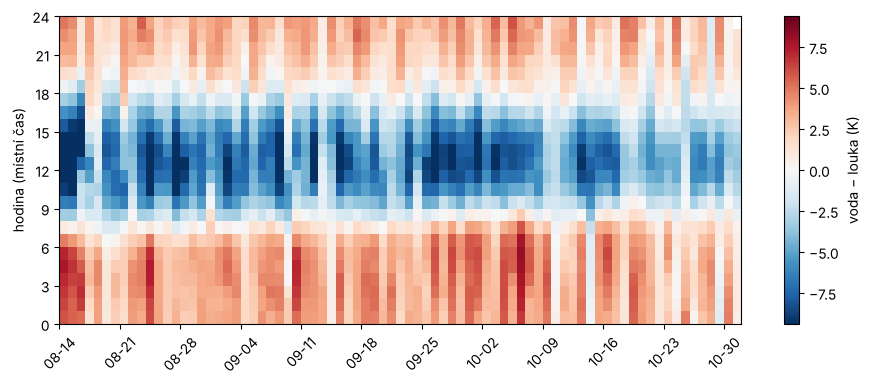

podíl dní, kdy je |voda − louka| ≥ 3 K, podle hodiny (%):
hod    0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16    17   18   19    20    21    22    23
%    62.0  62.0  66.0  68.0  68.0  66.0  48.0  15.0  13.0  49.0  76.0  91.0  92.0  91.0  86.0  73.0  41.0  13.0  3.0  8.0  25.0  41.0  46.0  54.0


In [4]:
A, B = "voda", "louka"        # ◀ parametr: dvojice povrchů
MIN_DT = 3                    # ◀ parametr: kontrast, který ještě v termosnímku spolehlivě rozlišíš (K)
h = (T[A] - T[B]).iloc[14 * 1440:].resample("h").mean()
grid = h.to_frame("d").assign(den=h.index.date, hod=h.index.hour).pivot(index="hod", columns="den", values="d")
lim = np.nanpercentile(np.abs(grid.values), 98)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(range(grid.shape[1] + 1), range(25), grid.values, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_yticks(range(0, 25, 3)); ax.set_ylabel("hodina (místní čas)")
ax.set_xticks(range(0, grid.shape[1], 7)); ax.set_xticklabels([str(c)[5:] for c in grid.columns[::7]], rotation=45)
plt.colorbar(im, label=f"{A} − {B} (K)"); plt.show()
ok = (grid.abs() >= MIN_DT).mean(axis=1) * 100
print(f"podíl dní, kdy je |{A} − {B}| ≥ {MIN_DT} K, podle hodiny (%):"); print(ok.round(0).to_frame("%").T.to_string())

> **✏️ Úkol 3.** Ve kterých hodinách je kontrast vody a louky spolehlivě velký a ve kterých se povrchy slévají? Jak se překřížení posouvají od léta k podzimu a proč? Hledáš vlhká místa v louce (dvojice louka × voda): kdy bys letěl a proč spíš ráno než v poledne?

*Tvoje odpověď:* 

## 5. Vítr

Stejné počasí spočítáme ještě jednou se slabším a silnějším větrem (vítr vynásobíme). Ostatní veličiny zůstanou skutečné.

In [5]:
FACTORS = [0.5, 1, 2, 4]      # ◀ parametr: násobky skutečného větru
DAY_W = SUNNY                 # ◀ parametr: den
tab = {}
for f in FACTORS:
    d = simulate(w, wind_factor=f).loc[str(DAY_W)]
    tab[f"vítr ×{f}"] = {"asfalt max": d["asfalt"].max(), "louka min": d["louka"].min(), "asfalt − louka ve 13:00": (d["asfalt"] - d["louka"]).between_time("12:55", "13:05").mean()}
print(f"{DAY_W}: skutečný vítr v 10 m průměrně {w.wind_speed_10m.loc[str(DAY_W)].mean():.1f} m/s")
pd.DataFrame(tab).round(1)

2026-08-15: skutečný vítr v 10 m průměrně 1.0 m/s


,vítr ×0.5,vítr ×1,vítr ×2,vítr ×4
asfalt max,58.5,56.4,53.2,48.8
louka min,11.8,11.6,11.4,11.4
asfalt − louka ve 13:00,24.7,23.7,21.8,18.8


> **✏️ Úkol 4.** Jak se se silnějším větrem změní polední maximum asfaltu, ranní minimum louky a kontrast asfalt − louka? Proč vítr kontrasty v termosnímku zmenšuje? Jaký limit větru bys pro termální let doporučil?

*Tvoje odpověď:* 

## 6. Emisivita v kameře a fotovoltaika

Kamera měří vyzařování W = ε σ T⁴ + (1 − ε) σ T_odr⁴, kde druhý člen je odražené okolí. Teplotu z něj počítá s emisivitou ε_k a odraženou teplotou T_odr, které nastavíš v kameře. Zjednodušení: počítáme v celém spektru, ne jen v pásmu 8–14 µm, a odražené okolí bereme jako oblohu.

Pro kontrolu FV elektráren se doporučuje ozáření panelu aspoň 600 W/m² (IEA PVPS). Ozáření skloněné plochy máme z Open-Meteo.

In [6]:
EPS_CAM = 1.00                # ◀ parametr: emisivita nastavená v kameře (zkus 0,95 a 0,85)
T_REFL = 20.0                 # ◀ parametr: odražená teplota nastavená v kameře (°C)
HOURS = ["05:00", "13:00"]    # ◀ parametr: časy snímků
DAY_E = SUNNY                 # ◀ parametr: den
eps = pd.Series({n: v["eps"] for n, v in SURF.items()})
rows = {}
for hh in HOURS:
    tt = pd.Timestamp(f"{DAY_E} {hh}")
    Tk = T.loc[tt] + 273.15; Ld = T.attrs["Ld"].loc[tt]
    W = eps * SIG * Tk ** 4 + (1 - eps) * Ld
    Trad = ((W - (1 - EPS_CAM) * SIG * (T_REFL + 273.15) ** 4) / (EPS_CAM * SIG)) ** 0.25 - 273.15
    rows[f"{hh} skutečná"] = T.loc[tt]; rows[f"{hh} kamera"] = Trad; rows[f"{hh} chyba"] = Trad - T.loc[tt]
print(f"{DAY_E}, emisivita v kameře {EPS_CAM}, odražená teplota {T_REFL} °C")
print(pd.DataFrame(rows).round(1))

THRESH = 600                  # ◀ parametr: minimální ozáření panelu pro kontrolu FV (W/m²)
g = w.global_tilted_irradiance
ok = (g >= THRESH).groupby([g.index.to_period("M").rename("měsíc"), g.index.hour.rename("hodina")]).sum().unstack(fill_value=0)
print(f"\nPočet hodin s ozářením panelu (sklon {TILT}°, azimut {AZ}°) ≥ {THRESH} W/m² podle měsíce a hodiny:")
print(ok.loc[:, ok.sum() > 0].to_string())

2026-08-15, emisivita v kameře 1.0, odražená teplota 20.0 °C
          05:00 skutečná  05:00 kamera  05:00 chyba  13:00 skutečná  \
voda                18.4          18.2         -0.2            20.3   
louka               11.6          11.3         -0.3            32.0   
asfalt              15.6          14.7         -0.9            55.7   
les                 10.0           9.8         -0.3            33.2   
FV panel            11.3           9.1         -2.3            50.9   

          13:00 kamera  13:00 chyba  
voda              20.2         -0.1  
louka             31.6         -0.4  
asfalt            53.8         -1.9  
les               32.8         -0.4  
FV panel          45.6         -5.3  

Počet hodin s ozářením panelu (sklon 35°, azimut 0°) ≥ 600 W/m² podle měsíce a hodiny:
hodina   10  11  12  13  14  15  16
měsíc                              
2026-07   1   1   1   1   1   1   0
2026-08  17  17  20  20  19  17   7
2026-09   9  15  16  13  15   6   0
2026-10   0   7 

> **✏️ Úkol 5.** S emisivitou 1,00 v kameře: který povrch se od své skutečné teploty liší nejvíc a proč FV panel vypadá chladnější, než je? Nastav 0,95 a pak 0,85: který povrch je teď správně a které ne? Proč je chyba v noci jiná než v poledne (uvaž odraženou oblohu)?

*Tvoje odpověď:* 

> **✏️ Úkol 6.** Ve kterých měsících a hodinách bylo ozáření panelů aspoň 600 W/m²? Změň v kroku 1 sklon na 60° a azimut na −90° (východ) a buňky spusť znovu: jak se okno pro kontrolu posune? Proč je kontrast vadného nebo odpojeného modulu při slabém slunci malý?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Spolužáci mohou mít notebook pro jiné místo (Suchdol, Brno, Hluboká nad Vltavou). Porovnejte pro stejné datum amplitudu teploty asfaltu a louky a čas překřížení. Liší se víc kvůli počasí toho dne, nebo kvůli místu?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744 (dlouhovlnné záření jasné oblohy).
- Crawford, T. M., Duchon, C. E. (1999). An improved parameterization for estimating effective atmospheric emissivity. *Journal of Applied Meteorology* 38, 474–480 (vliv oblačnosti).
- Oke, T. R. (1987). *Boundary Layer Climates*, 2. vyd. Routledge (tepelná vodivost a kapacita asfaltu a půdy, albeda).
- Maes, W. H. (2025). Practical guidelines for performing UAV mapping flights with snapshot sensors. *Remote Sensing* 17(4), 606. https://doi.org/10.3390/rs17040606 (plánování mapovacích letů včetně termálních).
- IEA PVPS Task 13 (2018). *Review on Infrared and Electroluminescence Imaging for PV Field Applications*, Report IEA-PVPS T13-10:2018 (emisivita skla 0,85, ozáření ≥ 600 W/m²).
- Přestup tepla prouděním h = 5,7 + 3,8 U (McAdams), tlak nasycených par Magnusovým vzorcem (WMO-No. 8, 2018).

### Jak citovat

OpenSkyLab (2026). Kdy letět s termokamerou: teplota povrchů ze skutečného počasí [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/thermal_timing_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*